In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from workload_data_loader_30064789 import load_workload_instance

In [2]:
n, m, utilities, demands, capacities = load_workload_instance("multi_resource_n28_m2.txt")


df = pd.DataFrame({"utility": utilities, **{f"resource_{i+1}": demands[i] for i in range(m)}})
print(demands)

[[ 45.   0.  85. 150.  65.  95.  30.   0. 170.   0.  40.  25.  20.   0.
    0.  25.   0.   0.  25.   0. 165.   0.  85.   0.   0.   0.   0. 100.]
 [ 30.  20. 125.   5.  80.  25.  35.  73.  12.  15.  15.  40.   5.  10.
   10.  12.  10.   9.   0.  20.  60.  40.  50.  36.  49.  40.  19. 150.]]


In [3]:
def evaluate(solution):
    # m is the number of resource bounds, in this case it will be 2
    # sum(iterable, start), if no np.zeros, the weight will be out of bounds as a set
    weight = sum((demands[:, i] for i in solution), np.zeros(m))
    value = sum(utilities[i] for i in solution)
    return weight, value

def fits(weight):
    return np.all(weight <= capacities)  # checks if all the resources under the capacity

def penalized_score(solution, penalty_weight=2000):
    weight, value = evaluate(solution)
    excess = np.maximum(0, weight - capacities)  # overflow per resource
    return value - penalty_weight * np.sum(excess)


def hill_climbing(seed=None, penalty_weight=2000):
    if seed is None:
        solution = set()  # Set up an empty starting solution
    else:
        np.random.seed(seed)
        # Random starting subset (may be infeasible; penalty guides it to feasibility)
        solution = {i for i in range(n) if np.random.rand() < 0.5}

    history = []
    while True:
        current_score = penalized_score(solution, penalty_weight)
        history.append(current_score)
        best_neighbor = solution #convert to best neighbor and best value to compare
        best_score = current_score

        # Neighbors: add, remove, or swap one model
        for i in range(n):  #n: the number of models, in this case: 28
            if i not in solution:
                candidate = solution | {i}  # Add the neighbor
                score = penalized_score(candidate, penalty_weight)

                if score > best_score:
                    best_neighbor = candidate
                    best_score = score

            else:
                candidate = solution - {i}  # Remove
                score = penalized_score(candidate, penalty_weight)

                if score > best_score:
                    best_neighbor = candidate
                    best_score = score


                for j in range(n):
                    if j not in solution:
                        candidate = (solution - {i}) | {j}  # Swap the resources values
                        score = penalized_score(candidate, penalty_weight)

                        if score > best_score:
                            best_neighbor = candidate
                            best_score = score

        # Stop if no improvement
        if best_neighbor == solution:
            break

        solution = best_neighbor

    return solution, history

# Show result
solution, _ = hill_climbing()
weight, value = evaluate(solution)

print("Selected models:")
for i in sorted(solution):
    print("Model", i, "- Demands:", demands[:, i], "Utility:", utilities[i])

print("Total resource used:", weight, "/ Capacity:", capacities)
print("Total utility:", value)


Selected models:
Model 2 - Demands: [ 85. 125.] Utility: 22507.0
Model 4 - Demands: [65. 80.] Utility: 14148.0
Model 6 - Demands: [30. 35.] Utility: 4650.0
Model 7 - Demands: [ 0. 73.] Utility: 30800.0
Model 9 - Demands: [ 0. 15.] Utility: 4975.0
Model 10 - Demands: [40. 15.] Utility: 1160.0
Model 13 - Demands: [ 0. 10.] Utility: 11880.0
Model 18 - Demands: [25.  0.] Utility: 110.0
Model 20 - Demands: [165.  60.] Utility: 24355.0
Model 22 - Demands: [85. 50.] Utility: 11748.0
Model 23 - Demands: [ 0. 36.] Utility: 4550.0
Total resource used: [495. 499.] / Capacity: [500. 500.]
Total utility: 130883.0


In [4]:
results = []
times = []
histories = []
best_sol = None
best_val = -1

for run in range(20):
    t0 = time.perf_counter()
    sol, hist = hill_climbing(seed=run)
    times.append(time.perf_counter() - t0)

    weight, value = evaluate(sol)
    results.append(value)
    histories.append(hist)
    if value > best_val:
        best_val = value
        best_sol = sol

print("Best:", max(results))
print("Mean:", np.mean(results))
print("Median:", np.median(results))
print("Std:", np.std(results))
print(f"Mean runtime: {np.mean(times):.4f}s | Total runtime: {np.sum(times):.4f}s")
print("Best models:", sorted(best_sol))
print("Best resource used:", evaluate(best_sol)[0], "/", capacities)


Best: 129173.0
Mean: 117007.7
Median: 119121.0
Std: 9866.870928009548
Mean runtime: 0.0209s | Total runtime: 0.4179s
Best models: [2, 4, 6, 7, 9, 10, 12, 13, 16, 20, 22, 26]
Best resource used: [490. 497.] / [500. 500.]


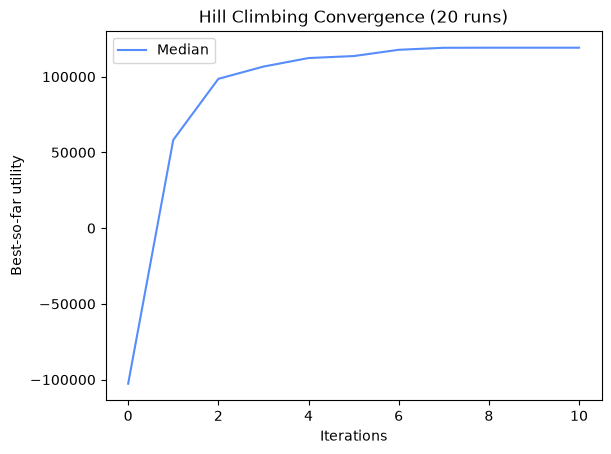

In [5]:
# Pad shorter runs with their final value so history is a 2D array (runs, iterations)
max_len = max(len(h) for h in histories) #max len of all runs (20)
history = np.array([h + [h[-1]] * (max_len - len(h)) for h in histories]) #fill an array with less iteration than the array have highest number of iterations to avoid errors of shapes when representing in graphs

best_so_far = np.maximum.accumulate(history, axis=1)
med = np.median(best_so_far, axis=0)
plt.plot(med, label="Median")
plt.xlabel("Iterations")
plt.ylabel("Best-so-far utility")
plt.title("Hill Climbing Convergence (20 runs)")
plt.legend()
plt.show()


#### Part 1: Baseline Discrete Local Search
For this part, I'm using a baseline local search (hill-climbing) to find best models to have best result.The model is a basic model with add and remove operators with a static constraint handling algorithm, and the reason why I choose local search because the dataset is small and stated that it is used for baseline local search, testing and validation, there is 1 problem of this model is that the randomize might not work, the model can be not improved everytime it runs as it shows no learning from times to times, for example, first iteration can give a good value/result, but it will give less value result in the next one, which consumes a lot of computation resources, and not use the resources to find a good solution. At the same time I have applied static penalty constrant to approach constraint handling, this constrant is easy to apply and preserve the result, however, the critical disadvange of this approach is that it needs its panalty weight choosen carefully. As the result of 20 runs (for-loop), the mean time that this model finds a solution is 0.0830s, total time to complete the for-loop is around 1.6s. The best models are 2, 4, 6, 7, 9, 10, 12, 13, 16, 20, 22 and 26 to generate the highest value, and also it nearly uses all resources with 490/500 and 497/500.Regarding the convergence graph, in all 20 runs, the maximum iterations to find the best solution is 11 iterations. In the y-axis, it shows the best-so-far metrics, however, in iteration 1, it will have minus variable to go because some runs can exceed the capacity, which penalties hit it. Overall the graph show that best-so-far value gradually increased.

In [6]:
print(med)

[-102688.    58230.5   98560.5  106650.   112294.5  113590.5  117738.
  119066.   119121.   119121.   119121. ]


In [7]:
# Part 2: Genetic Algorithm on Instance 2 (n = 90, m = 5)
from workload_data_loader_30064789 import load_workload_instance
n2, m2, utilities2, demands2, capacities2 = load_workload_instance("multi_resource_n90_m5 (1).txt")

population_size = 50 # 50 possible solutions
generations = 200
mutation_rate = 1 / n2   # flip ~1 bit per child on average

# Efficiency ratio for greedy repair (higher utility per normalized resource = better)
efficiency = utilities2 / np.sum(demands2 / capacities2[:, None], axis=0) #Original: value / capacity
drop_order = np.argsort(efficiency)   # worst efficiency in the first place of the array


In [8]:
def static_penalty(chromosome, penalty_weight=350):
    total_weight = np.dot(demands2, chromosome)
    total_value = np.dot(utilities2, chromosome)
    excess = np.maximum(0, total_weight - capacities2)
    return total_value - penalty_weight * np.sum(excess)

def dynamic_penalty(chromosome, gen, max_gen, start_weight=50, end_weight=350):
    weight_now = start_weight + (end_weight - start_weight) * (gen / max(max_gen - 1, 1))
    total_weight = np.dot(demands2, chromosome)
    total_value = np.dot(utilities2, chromosome)
    excess = np.maximum(0, total_weight - capacities2)
    return total_value - weight_now * np.sum(excess)

def greedy_repair(chromosome):
    repaired = chromosome.copy()
    used_resources = np.dot(demands2, repaired)
    # Drop lowest-efficiency models until all constraints fit
    for i in drop_order:
        if np.all(used_resources <= capacities2):
            break
        if repaired[i] == 1:
            repaired[i] = 0
            used_resources = used_resources - demands2[:, i] #minus the resources that is switched to 0, when for loop again, compare the used resource with the capacities
    return repaired


In [9]:
def ga_fitness(chromosome):
    return np.dot(utilities2, chromosome) #calculate the value of the solution

def create_chromosome():
    return np.random.randint(0, 2, size=n2) #randomly create chromosome, it should use greedy repair from gen 0


In [10]:
def tournament_selection(population, k=3, fitness_fn=ga_fitness):
    idx = np.random.choice(len(population), size=k, replace=False) #choosing tournament of 3 candidates, returns the best candidate
    candidates = [population[i] for i in idx] #list of all candidates
    return max(candidates, key=fitness_fn)


In [11]:
def crossover(parent1, parent2):
    point = np.random.randint(1, n2)  #randomizing the index to crossover
    child1 = np.concatenate([parent1[:point], parent2[point:]])
    child2 = np.concatenate([parent2[:point], parent1[point:]])
    return child1, child2

def uniform_crossover(parent1, parent2):
    mask = np.random.rand(n2) < 0.5
    child1 = np.where(mask, parent1, parent2)
    child2 = np.where(mask, parent2, parent1)
    return child1, child2


In [12]:
def mutation(chromosome): #randomly flips from 0 to 1 to see new models
    for i in range(n2):
        if np.random.rand() < mutation_rate: #generate a random variable from 0 to 1, compare it with the mutation rate
            chromosome[i] = 1 - chromosome[i]
    return chromosome
    #the mutation rate is the probability of switching models in a solution


In [13]:
def genetic_algorithm(seed=None, crossover_fn=crossover, constraint_mode="repair"):
    if seed is not None: #randomize the models
        np.random.seed(seed)

    population = [create_chromosome() for _ in range(population_size)] #create 50 candidate solutions
    if constraint_mode == "repair":
        population = [greedy_repair(c) for c in population]
    history = [] #records best values times to times

    for gen in range(generations):  #generations: number of steps to the last solution, runs for loop 200 times = runs 200 genetic algroithm until last solution
        if constraint_mode == "repair":
            fitness_fn = ga_fitness
        elif constraint_mode == "static":
            fitness_fn = static_penalty
        else:
            fitness_fn = lambda c, g=gen: dynamic_penalty(c, g, generations)

        best = max(population, key=fitness_fn) #returns the best solution based on fitness
        history.append(fitness_fn(best)) #record history
        new_population = [best.copy()]  # keep best chromosome

        while len(new_population) < population_size:
            parent1 = tournament_selection(population, fitness_fn=fitness_fn) #select 2 parents
            parent2 = tournament_selection(population, fitness_fn=fitness_fn)
            child1, child2 = crossover_fn(parent1, parent2)  # generate 2 children
            child1 = mutation(child1)
            child2 = mutation(child2)
            if constraint_mode == "repair":
                child1 = greedy_repair(child1)
                child2 = greedy_repair(child2)
            new_population.append(child1)
            if len(new_population) < population_size: #avoid having more solutions than the population size
                new_population.append(child2)

        population = new_population

    final_fitness = ga_fitness if constraint_mode == "repair" else static_penalty
    best_solution = max(population, key=final_fitness)
    return best_solution, history

# Show result
best_solution, _ = genetic_algorithm(seed=42)
total_weight = np.dot(demands2, best_solution)
total_value = np.dot(utilities2, best_solution)

print("Selected models count:", int(np.sum(best_solution)))
print("Total resource used:", total_weight, "/ Capacity:", capacities2)
print("Total utility:", total_value)


Selected models count: 47
Total resource used: [1729. 1097. 2019. 1959. 2308.] / Capacity: [2100. 1100. 3300. 3700. 3600.]
Total utility: 11117.0


In [14]:
ga_results = []
ga_times = []
ga_histories = []
ga_best_sol = None
ga_best_val = -1

for run in range(30):
    t0 = time.perf_counter()
    sol, hist = genetic_algorithm(seed=run)
    ga_times.append(time.perf_counter() - t0)

    weight = np.dot(demands2, sol) #final weight
    value = np.dot(utilities2, sol) #final value
    ga_results.append(value)
    ga_histories.append(hist)
    if value > ga_best_val:
        ga_best_val = value
        ga_best_sol = sol

print("Best:", max(ga_results))
print("Mean:", np.mean(ga_results))
print("Median:", np.median(ga_results))
print("Std:", np.std(ga_results))
print(f"Mean runtime: {np.mean(ga_times):.4f}s | Total runtime: {np.sum(ga_times):.4f}s")
print("Best models:", np.where(ga_best_sol == 1)[0].tolist())
print("Best resource used:", np.dot(demands2, ga_best_sol), "/", capacities2)


Best: 11182.0
Mean: 11112.433333333332
Median: 11115.0
Std: 39.22642250093962
Mean runtime: 0.6918s | Total runtime: 20.7547s
Best models: [0, 3, 4, 6, 8, 9, 10, 11, 12, 15, 17, 18, 21, 22, 25, 29, 30, 33, 34, 38, 41, 42, 47, 48, 49, 50, 51, 53, 55, 57, 58, 59, 60, 61, 62, 63, 65, 66, 68, 69, 72, 73, 75, 77, 84, 85, 86, 87, 89]
Best resource used: [1784. 1100. 2098. 2062. 2435.] / [2100. 1100. 3300. 3700. 3600.]


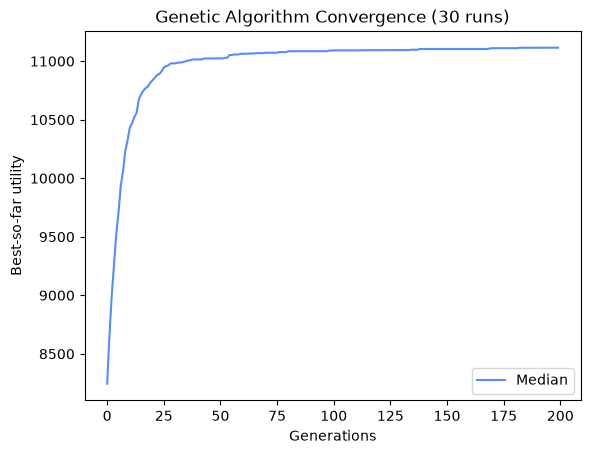

In [15]:
ga_history = np.array(ga_histories)
ga_best_so_far = np.maximum.accumulate(ga_history, axis=1)
ga_med = np.median(ga_best_so_far, axis=0)

plt.plot(ga_med, label="Median")
plt.xlabel("Generations")
plt.ylabel("Best-so-far utility")
plt.title("Genetic Algorithm Convergence (30 runs)")
plt.legend()
plt.show()


### Part 2: Advanced Metaheuristic Engineering
In this part, I have implemented an advanced population-based discrete metaheuristic, which is Genetic Algorithm and with Greddy Repair contrant handling. \
When changing the dataset, the local search might be not ideal, the first reason is that the local search only hit local optima, not global optima as it is only find a best solution and then in the next independent runs, it will show the result that equals value or less value to the previous results. From that I have used Genetic Algorithm to diversify the solution, not depending on the starting point to find the solution, so it solves the local optima problem. the output of the Genetic Algorithm is a list with 0 and 1, 0 is not choosing that model in that index and 1 is choosing that model in that index. There are steps to introduce GA:
- The generate first population: "population" variable
- Evaluate fitness: "ga_fitness" function
- Tournament parent selection
- crossover and mutation

Moreover, I have applied Greddy Repair which checks if the solution is infeasible or feasible, if the solution is infeasible, delete the models from the lowest efficiency until the solution is feasible, which fixes all the solutions into all feasible solution. For the result of running genetic algorithm, the best value of all solutions is 1116.0, the mean value is around 11122. The algorithm takes 14.23s to run all 30 independent runs, which is slower than the local search. However, the capacity used is [1741. 1099. 2222. 2083. 2306.] / [2100. 1100. 3300. 3700. 3600.], which does not use up all the capacities. Regarding the genetic convergence graph, it shows that the best-so-far value of the algorithm shoots up in early stage of genetic algorithm, however, from one point, it is slowly improving the best-so-far value from 11000 to around 11600, which the solutions are improving to get the better value.


In [16]:
ga_med

array([ 8245. ,  8652.5,  8993. ,  9260. ,  9520. ,  9704.5,  9936. ,
       10058. , 10233.5, 10324. , 10432.5, 10471.5, 10523. , 10560. ,
       10674.5, 10716.5, 10749. , 10769.5, 10784.5, 10814.5, 10837. ,
       10857.5, 10881.5, 10890. , 10912.5, 10944.5, 10958. , 10964.5,
       10981. , 10981. , 10981. , 10985.5, 10989. , 10989. , 10995. ,
       11001.5, 11006. , 11009.5, 11015. , 11015. , 11015. , 11015. ,
       11016.5, 11023.5, 11023.5, 11023.5, 11023.5, 11023.5, 11023.5,
       11023.5, 11023.5, 11023.5, 11029. , 11029. , 11052. , 11052. ,
       11057. , 11057. , 11057. , 11063. , 11063. , 11063. , 11064.5,
       11064.5, 11065.5, 11065.5, 11068.5, 11068.5, 11068.5, 11068.5,
       11072. , 11072. , 11072. , 11072. , 11072. , 11072. , 11077.5,
       11077.5, 11077.5, 11077.5, 11085. , 11085. , 11085. , 11085. ,
       11085. , 11085. , 11085. , 11085. , 11085. , 11085. , 11085. ,
       11085. , 11085. , 11085. , 11085. , 11085. , 11085. , 11085. ,
       11091. , 1109

In [17]:
uni_results = []
uni_times = []
uni_histories = []
uni_best_sol = None
uni_best_val = -1

for run in range(30):
    t0 = time.perf_counter()
    sol, hist = genetic_algorithm(seed=run, crossover_fn=uniform_crossover)
    uni_times.append(time.perf_counter() - t0)

    weight = np.dot(demands2, sol)
    value = np.dot(utilities2, sol)
    uni_results.append(value)
    uni_histories.append(hist)
    if value > uni_best_val:
        uni_best_val = value
        uni_best_sol = sol

print("Uniform Crossover (30 runs)")
print("Best:", max(uni_results))
print("Mean:", np.mean(uni_results))
print("Median:", np.median(uni_results))
print("Std:", np.std(uni_results))
print(f"Mean runtime: {np.mean(uni_times):.4f}s | Total runtime: {np.sum(uni_times):.4f}s")
print("Best models:", np.where(uni_best_sol == 1)[0].tolist())
print("Best resource used:", np.dot(demands2, uni_best_sol), "/", capacities2)


Uniform Crossover (30 runs)
Best: 11169.0
Mean: 11122.433333333332
Median: 11135.0
Std: 36.156772840260814
Mean runtime: 0.5841s | Total runtime: 17.5233s
Best models: [0, 4, 6, 8, 9, 10, 11, 12, 15, 17, 18, 21, 22, 25, 29, 30, 32, 33, 34, 38, 41, 42, 47, 48, 49, 50, 51, 53, 55, 57, 58, 59, 60, 61, 62, 63, 65, 66, 68, 69, 72, 73, 75, 77, 78, 84, 85, 86, 87]
Best resource used: [1777. 1100. 2121. 2057. 2384.] / [2100. 1100. 3300. 3700. 3600.]


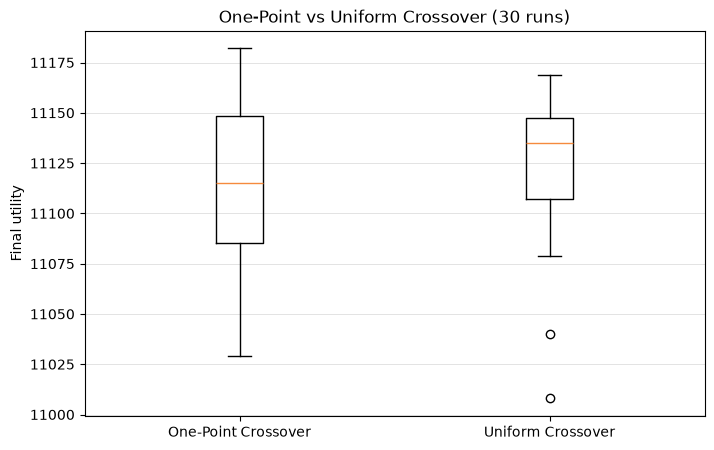

In [18]:
plt.figure(figsize=(8, 5))
plt.boxplot([ga_results, uni_results], tick_labels=["One-Point Crossover", "Uniform Crossover"])
plt.ylabel("Final utility")
plt.title("One-Point vs Uniform Crossover (30 runs)")
plt.grid(True, axis="y")
plt.show()


In [19]:
static_results = []
static_times = []
static_histories = []
static_feasible = 0
static_best_sol = None
static_best_val = -1

for run in range(30):
    t0 = time.perf_counter()
    sol, hist = genetic_algorithm(seed=run, crossover_fn=crossover, constraint_mode="static")
    static_times.append(time.perf_counter() - t0)

    weight = np.dot(demands2, sol)
    value = np.dot(utilities2, sol)
    if np.all(weight <= capacities2):
        static_feasible += 1
    static_results.append(value)
    static_histories.append(hist)
    if value > static_best_val and np.all(weight <= capacities2):
        static_best_val = value
        static_best_sol = sol

print("Static Penalty + One-Point Crossover (30 runs)")
print(f"Feasible runs: {static_feasible}/30")
print("Best:", max(static_results))
print("Mean:", np.mean(static_results))
print("Median:", np.median(static_results))
print("Std:", np.std(static_results))
print(f"Mean runtime: {np.mean(static_times):.4f}s | Total runtime: {np.sum(static_times):.4f}s")
print("Best models:", np.where(static_best_sol == 1)[0].tolist())
print("Best resource used:", np.dot(demands2, static_best_sol), "/", capacities2)


Static Penalty + One-Point Crossover (30 runs)
Feasible runs: 30/30
Best: 11191.0
Mean: 11133.2
Median: 11142.0
Std: 32.50271783507753
Mean runtime: 0.6279s | Total runtime: 18.8381s
Best models: [0, 4, 6, 8, 9, 10, 11, 12, 15, 17, 18, 21, 22, 25, 29, 30, 33, 34, 38, 39, 41, 42, 47, 48, 49, 50, 51, 53, 55, 57, 58, 59, 60, 61, 62, 63, 65, 66, 68, 69, 72, 73, 75, 77, 81, 82, 84, 85, 86, 87, 89]
Best resource used: [1777. 1100. 2259. 2232. 2418.] / [2100. 1100. 3300. 3700. 3600.]


In [ ]:
dynamic_results = []
dynamic_times = []
dynamic_histories = []
dynamic_feasible = 0
dynamic_best_sol = None
dynamic_best_val = -1

for run in range(30):
    t0 = time.perf_counter()
    sol, hist = genetic_algorithm(seed=run, crossover_fn=crossover, constraint_mode="dynamic")
    dynamic_times.append(time.perf_counter() - t0)

    weight = np.dot(demands2, sol)
    value = np.dot(utilities2, sol)
    if np.all(weight <= capacities2):
        dynamic_feasible += 1
    dynamic_results.append(value)
    dynamic_histories.append(hist)
    if value > dynamic_best_val and np.all(weight <= capacities2):
        dynamic_best_val = value
        dynamic_best_sol = sol

print("Dynamic Penalty + One-Point Crossover (30 runs)")
print(f"Feasible runs: {dynamic_feasible}/30")
print("Best:", max(dynamic_results))
print("Mean:", np.mean(dynamic_results))
print("Median:", np.median(dynamic_results))
print("Std:", np.std(dynamic_results))
print(f"Mean runtime: {np.mean(dynamic_times):.4f}s | Total runtime: {np.sum(dynamic_times):.4f}s")
print("Best models:", np.where(dynamic_best_sol == 1)[0].tolist())
print("Best resource used:", np.dot(demands2, dynamic_best_sol), "/", capacities2)


In [ ]:
repair_med = np.median(np.maximum.accumulate(np.array(ga_histories), axis=1), axis=0)
static_med = np.median(np.maximum.accumulate(np.array(static_histories), axis=1), axis=0)
dynamic_med = np.median(np.maximum.accumulate(np.array(dynamic_histories), axis=1), axis=0)

plt.figure(figsize=(10, 5))
plt.plot(repair_med, color="red", label="Greedy Repair")
plt.plot(static_med, color="green", label="Static Penalty")
plt.plot(dynamic_med, color="blue", label="Dynamic Penalty")
plt.ylim(8000, 11250)
plt.xlabel("Generations")
plt.ylabel("Best-so-far utility")
plt.title("Constraint Handling Convergence Comparison (30 runs)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
from scipy.stats import mannwhitneyu
_, p_val = mannwhitneyu(ga_results, uni_results, alternative="two-sided")
print(f"p = {p_val:.4f}")
if p_val < 0.05:
    print("Reject H0: statistically significant difference between One-Point and Uniform Crossover")
else:
    print("Fail to reject H0: no statistically significant difference between One-Point and Uniform Crossover")


In [ ]:
pairs = [
    ("Greedy Repair vs Static Penalty", ga_results, static_results),
    ("Greedy Repair vs Dynamic Penalty", ga_results, dynamic_results),
    ("Static Penalty vs Dynamic Penalty", static_results, dynamic_results),
]
for name, a, b in pairs:
    _, p_val = mannwhitneyu(a, b, alternative="two-sided")
    print(f"{name}: p = {p_val:.4f}")
    if p_val < 0.05:
        print("  Reject H0: statistically significant difference")
    else:
        print("  Fail to reject H0: no statistically significant difference")


### Part 3: Empirical Study & Hypothesis Testing
In this part, I have modified 2 things to test, which is crossover and constraint handling. Regarding the crossovers, I have implemented 2 crossovers to the genetic algorithm, one is One-point crossover and one is uniform crossover with evaluations using box plot and Mann-Whitney U statistical testing. Specifically, the null hypothesis is no statistically significant difference between 2 crossovers, while the alternative hypothesis is statistically difference between 2 crossovers. Walking through the advantages and disadvantages, the one-point crossover not only has an advantage of applying this algorithm easier and faster but also preserve the first block at first positions, which protects some models are good with each other. However, while it preserves the first blocks, it is hard to preserve the pairs of good models containing the models in the first blocks and in the last blocks of the chromosomes, can mostly break all the good genes based on the dataset. In contrast, the uniform solves this problem by using probability, in which have more probability to generate chromosomes which are good together on the first and last blocks. However, the trade-off is clear, it has 50% chance of breaking some good pairs of models, which might break good pairs of models next to each other. Next, looking into the box plot, we can see that the best utilities of one-point crossover is slightly better than uniform crossover, however, the average and the minimum utilities of uniform crossover is higher than one-point crossover, which means the uniform crossover is not exactly discovery algorithm than the one-point crossover. Moreover, for the runtime, the basic one-point crossover is faster than uniform crossover, which makes the one-point algorithm is more efficient than the uniform crossover, it generates more utilities while maintaining fast runtime. Into the Statistical test, the p-value is 0.3039 which fails the null hypothesis, so changing the crossover means nothing as there are no diffirences between 2 crossovers, this might because all the algorithm in genetic algorithm is more important than the crossovers themselves.

In the next experiment, I have implemented more constraint handling like static penalty and dynamic penalty to see if the penalty algorithms can beat greedy repair algorithm. While the greedy repairs can ensure the feasibility across all solutions, it can be inefficient by deleting the most inefficient runs when the solution is infeasible, as the result, the solution is not using all the capacities to have a good results. Into the penalty algorithms, while the penalty algorithms can preserve useful information from near-feasible candidates , I should select the penalty weight carefully to optimize the algorithm. As the result of the graph the best-so-far value of greedy repair value has a strong start to 50th generation, but it is not improving from 50th generation. While the greedy repair best-so-far value stop improving, the penalty algorithm grows its best-so-far value and pass the greedy repair's best-so-far value at the end. In addition, the runtime of all constraint handling algorithms are the same except for greedy repair, which its runtime is 15 seconds compared to around 14 seconds of static penalty and dynamic penalty. On the other hand, when it comes to basic statistics, the median value of static penalty is 11142, which slightly higher than dynamic penalty and significantly higher than greedy repair, also, the best value of the static penalty and dynamic penalty is 11191, which is better than greedy repair constraint handling. Moreover, based on Mann-Whitney U statistic test, when comparing the performance of greedy repair between 2 penalty algorithm, those reject the null hypothesis, 2 penalty algorithms have a higher performance than greedy repair, while when comparing 2 penalty constraint handling, the result shows that it is failed to reject Null Hypothesis, which mean there is no difference between 2 algorithms. Therefore, it can be concluded that using penalty constraint handling is better than using Greedy repair.